# Предсказание стоимости подержанных автомобилей

Учебный проект по основам машинного обучения: EDA, подготовка данных, сравнение моделей и проверка гипотез.

## Исходные гипотезы

1. **OLS покажет меньшую MAE, чем дерево решений.** Предполагаем, что зависимости цены от характеристик автомобиля достаточно хорошо описываются линейной моделью.
2. **Ridge с подобранным `alpha` покажет меньшую MAE, чем OLS.** Предполагаем, что регуляризация поможет справиться с мультиколлинеарностью признаков.
3. **Исключение одного из коррелирующих признаков (`|r| > 0.6`) незначительно изменит качество модели прогнозирования цены автомобиля.**
4. **Совместное исключение `accident`, `model_year` и `clean_title` незначительно изменит качество предсказания цены**, несмотря на важность этих характеристик при покупке автомобиля.
5. **При глубине дерева больше 5 начнётся переобучение:** обучающая MAE будет уменьшаться, а средняя валидационная MAE увеличиваться.
6. **Ridge на логарифме цены покажет меньшую MAE, чем Ridge на исходной цене.** Перед оценкой прогнозы преобразуются обратно в доллары.

Гипотезы зафиксированы в README до подробного EDA и обучения.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

## 1. Загрузка данных и начальный анализ данных

In [2]:
from pathlib import Path

# В локальном клоне CSV уже лежит рядом с блокнотом.
# В Colab загрузите приложенный к репозиторию used_cars.csv.
if not Path('used_cars.csv').is_file():
    from google.colab import files
    files.upload()

if not Path('used_cars.csv').is_file():
    raise FileNotFoundError('Поместите used_cars.csv рядом с блокнотом.')

In [3]:
df = pd.read_csv('used_cars.csv')
df.head().style.format({'price': lambda value: str(value).replace('$', '')})

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capability,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"10,300"
1,Hyundai,Palisade SEL,2021,"34,742 mi.",Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,"38,005"
2,Lexus,RX 350 RX 350,2022,"22,372 mi.",Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,nan,"54,598"
3,INFINITI,Q50 Hybrid Sport,2015,"88,900 mi.",Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric Hybrid,7-Speed A/T,Black,Black,None reported,Yes,"15,500"
4,Audi,Q3 45 S line Premium Plus,2021,"9,835 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,nan,"34,999"


In [4]:
df.shape

(4009, 12)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4009 entries, 0 to 4008
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   brand         4009 non-null   str  
 1   model         4009 non-null   str  
 2   model_year    4009 non-null   int64
 3   milage        4009 non-null   str  
 4   fuel_type     3839 non-null   str  
 5   engine        4009 non-null   str  
 6   transmission  4009 non-null   str  
 7   ext_col       4009 non-null   str  
 8   int_col       4009 non-null   str  
 9   accident      3896 non-null   str  
 10  clean_title   3413 non-null   str  
 11  price         4009 non-null   str  
dtypes: int64(1), str(11)
memory usage: 376.0 KB


* В `fuel_type`, `accident`, `clean_title` есть пропуски.
* `milage` и `price` загружены как строки из-за единиц измерения и разделителей разрядов.

Преобразуем `milage` и `price` в числа: удаляем запятые, обозначение миль и знак доллара.

In [6]:
df['milage'] = (df['milage']
                .str.replace(',', '', regex=False)
                .str.replace('mi.', '', regex=False)
                .astype(int))

df['price'] = (df['price']
                .str.replace('$', '', regex=False)
                .str.replace(',', '', regex=False)
                .astype(int))

In [7]:
df[['milage', 'price']].head()

,milage,price
0,51000,10300
1,34742,38005
2,22372,54598
3,88900,15500
4,9835,34999


In [8]:
df[['milage', 'price']].dtypes

milage    int64
price     int64
dtype: object

## 2. EDA (Exploratory Data Analysis)

Разделим данные: 80% для разработки и кросс-валидации, 20% для отложенного теста. Далее исследуем только `df_train`. Отложенный тест используется только в финальном разделе после выбора моделей и настроек по кросс-валидации.

In [9]:
from sklearn.model_selection import train_test_split

In [10]:
df_train, df_test = train_test_split(df, test_size=0.2, random_state=142)

print('Обучающая выборка:', df_train.shape)
print('Тестовая выборка:', df_test.shape)

Обучающая выборка: (3207, 12)
Тестовая выборка: (802, 12)


### 2.1. Числовые признаки и распределения

In [11]:
df_train.describe().round(2)

,model_year,milage,price
count,3207.00,3207.00,3207.00
mean,2015.50,64987.38,44994.82
std,6.09,51997.38,84351.55
min,1993.00,100.00,2300.00
25%,2012.00,23142.00,17000.00
50%,2017.00,53433.00,31331.00
75%,2020.00,94245.50,49897.50
max,2024.00,399000.00,2954083.00


* Средний пробег выше медианного; максимальный пробег заметно больше 75-го процентиля. Это указывает на правостороннюю асимметрию и кандидатов в выбросы.
* Средняя цена значительно выше медианы; отдельные очень дорогие автомобили растягивают правый хвост. Само по себе это не доказывает ошибочность объявлений.

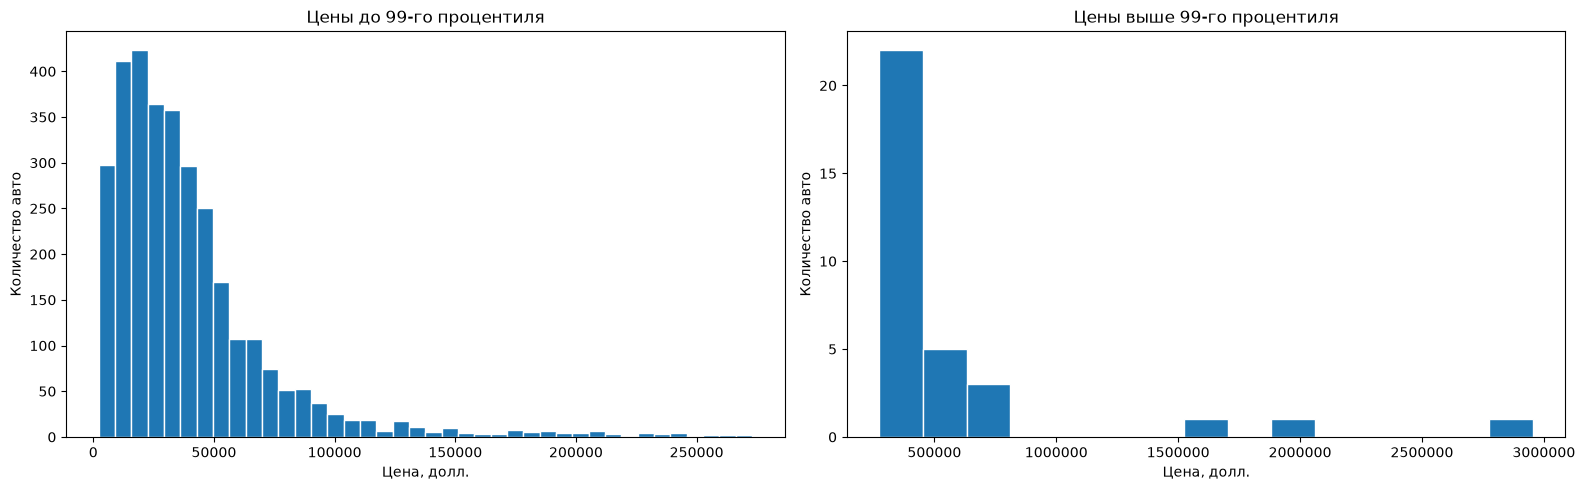

In [12]:
prices = df_train['price']
limit = prices.quantile(0.99)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].hist(prices[prices <= limit], bins=40, edgecolor='white')
axes[0].set(title='Цены до 99-го процентиля',
            xlabel='Цена, долл.', ylabel='Количество авто')

axes[1].hist(prices[prices > limit], bins=15, edgecolor='white')
axes[1].set(title='Цены выше 99-го процентиля',
            xlabel='Цена, долл.', ylabel='Количество авто')
axes[1].ticklabel_format(axis='x', style='plain')

plt.tight_layout()
plt.show()


Распределение цены имеет выраженную правостороннюю асимметрию. Основная масса автомобилей стоит несколько десятков тысяч долларов, но встречаются объявления дороже миллиона. Разделение графиков по 99-му процентилю служит только визуализации: наблюдения из обучения не удаляются.

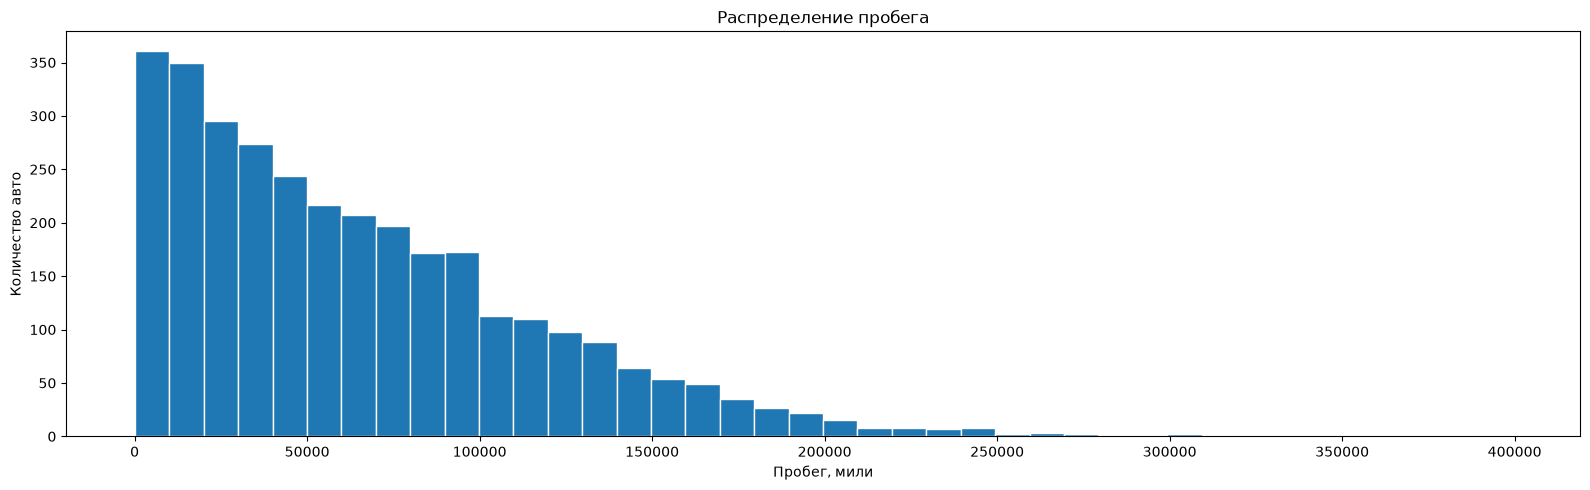

In [13]:
fig, ax = plt.subplots(figsize=(16, 5))

ax.hist(df_train['milage'], bins=40, edgecolor='white')
ax.set(title='Распределение пробега',
       xlabel='Пробег, мили', ylabel='Количество авто')

plt.tight_layout()
plt.show()

* Распределение пробега имеет правостороннюю асимметрию. Автомобили с небольшим пробегом встречаются чаще. С увеличением пробега количество наблюдений в целом сокращается, формируется длинный правый хвост. Автомобили с пробегом более 200 тысяч встречаются редко.

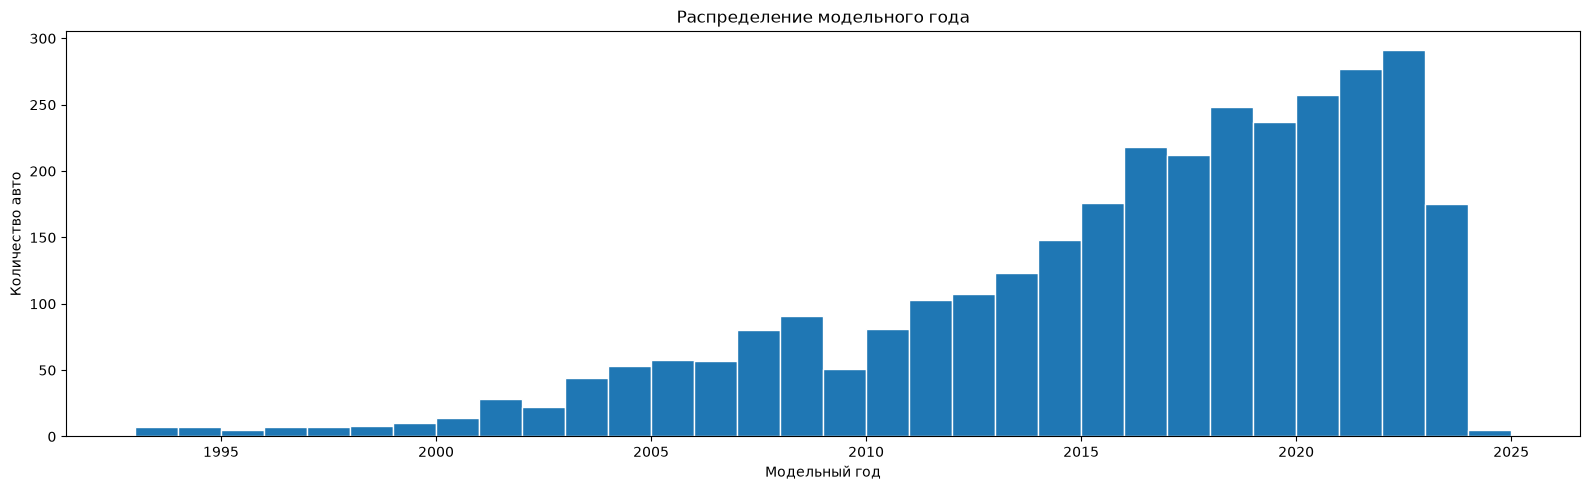

In [14]:
fig, ax = plt.subplots(figsize=(16, 5))
bins = range(df_train['model_year'].min(), df_train['model_year'].max() + 2)

ax.hist(df_train['model_year'], bins=bins, edgecolor='white')
ax.set(title='Распределение модельного года',
       xlabel='Модельный год', ylabel='Количество авто')

plt.tight_layout()
plt.show()

* В обучающей выборке преобладают автомобили с 2016 по 2023 год выпуска. Автомобили до 2000 года встречаются редко. Автомобилей 2024 года также немного.

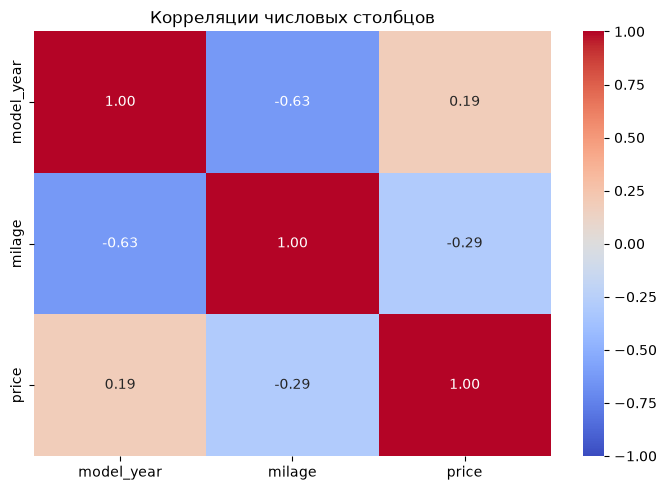

In [15]:
eda_numeric_cols = ['model_year', 'milage', 'price']
corr = df_train[eda_numeric_cols].corr()

fig, ax = plt.subplots(figsize=(7, 5))

sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1, ax=ax)

ax.set_title('Корреляции числовых столбцов')

plt.tight_layout()
plt.show()

* Более новым автомобилям в целом соответствует меньший пробег. Это заметная отрицательная линейная связь.
* Более новым автомобилям в целом соответствует более высокая цена, но парная линейная связь слабая.
* С увеличением пробега цена в целом снижается, однако линейная связь также сравнительно слабая.

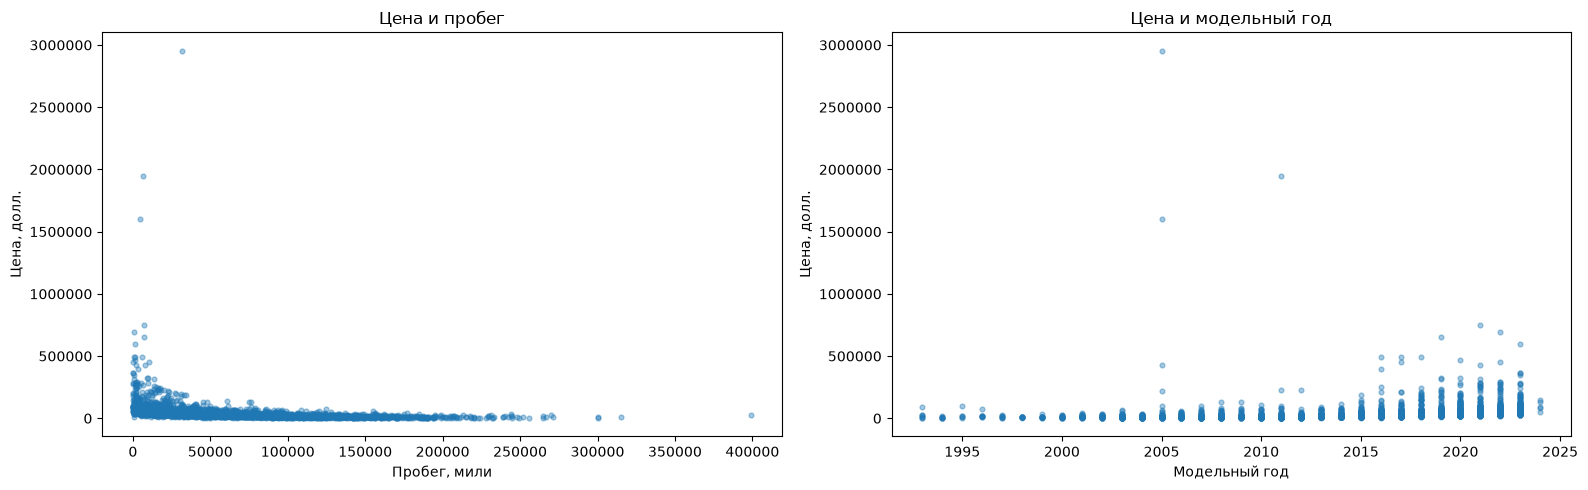

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].scatter(df_train['milage'], df_train['price'],
                s=12, alpha=0.4)
axes[0].set(title='Цена и пробег',
            xlabel='Пробег, мили', ylabel='Цена, долл.')
axes[0].ticklabel_format(axis='y', style='plain')

axes[1].scatter(df_train['model_year'], df_train['price'],
                s=12, alpha=0.4)
axes[1].set(title='Цена и модельный год',
            xlabel='Модельный год', ylabel='Цена, долл.')
axes[1].ticklabel_format(axis='y', style='plain')

plt.tight_layout()
plt.show()

* Автомобили с наиболее высокой ценой имеют небольшой пробег, но относятся к разным годам выпуска, включая не самые новые. Предполагаем, что их высокая стоимость связана также с другими характеристиками например, маркой и конкретной моделью автомобиля.

In [17]:
df_train.nlargest(5, 'price')[
    ['brand', 'model', 'model_year', 'milage', 'price']
]

,brand,model,model_year,milage,price
693,Maserati,Quattroporte Base,2005,32000,2954083
229,Bugatti,Veyron 16.4 Grand Sport,2011,6330,1950995
3046,Porsche,Carrera GT Base,2005,4400,1599000
1356,Lamborghini,Aventador SVJ Base,2021,6987,749950
624,Rolls-Royce,Cullinan,2022,398,695000


### 2.2. Категориальные признаки и скрытые пропуски

In [18]:
for col in ['fuel_type', 'accident', 'clean_title']:
  print(col)
  display(df_train[col].value_counts(dropna=False))

fuel_type


fuel_type
Gasoline          2657
Hybrid             155
NaN                127
E85 Flex Fuel      110
Diesel              96
–                   33
Plug-In Hybrid      28
not supported        1
Name: count, dtype: int64

accident


accident
None reported                             2318
At least 1 accident or damage reported     803
NaN                                         86
Name: count, dtype: int64

clean_title


clean_title
Yes    2740
NaN     467
Name: count, dtype: int64

В `fuel_type` встречаются прочерки и `not supported`. Проверим соответствующие описания двигателя, чтобы понять смысл этих значений.

In [19]:
df_train.loc[
    df_train['fuel_type'] == 'not supported',
    ['brand', 'model', 'fuel_type', 'engine']
]

,brand,model,fuel_type,engine
2894,Toyota,Mirai Limited,not supported,182.0HP Electric Motor Hydrogen Fuel


В строке `not supported` указан Toyota Mirai с описанием электрического двигателя и водородных топливных элементов. В принятой упрощённой группировке он относится к `Electric`.

In [20]:
df_train.loc[
    df_train['fuel_type'].isin(['–', '—', '-']),
    ['brand', 'model', 'fuel_type', 'engine']
]

,brand,model,fuel_type,engine
2103,Volvo,850 Turbo,–,–
3952,Dodge,Ram 3500 Quad Cab DRW,–,–
3984,Toyota,Land Cruiser Base,–,–
1083,Dodge,Challenger R/T,–,–
2608,Jeep,Wrangler S,–,–
257,Toyota,Land Cruiser Base,–,–
2505,Dodge,Challenger SRT8,–,–
1681,Acura,Integra GS-R,–,–
2574,Cadillac,DeVille Base,–,–
995,Dodge,Challenger R/T Scat Pack,–,–


* В `fuel_type` на обучающей выборке: 127 пропусков, 33 прочерка и одно значение `not supported`.
* В просмотренных строках с прочерком в `fuel_type` описание `engine` также отсутствует и обозначено прочерком. Такие обозначения не обнаруживаются через `.isna()`.
* Тип топлива и описание двигателя могут содержать связанную информацию. Это наблюдение не является основанием считать их взаимозаменяемыми; в итоговой модели `fuel_type` сохранён.

In [21]:
df_train.loc[
    df_train['fuel_type'].isna(),
    ['brand', 'model', 'fuel_type', 'engine']
].head(127)

,brand,model,fuel_type,engine
2066,Chevrolet,Bolt EV LT,NaN,200.0HP Electric Motor Electric Fuel System
1901,Tesla,Model S Performance,NaN,778.0HP Electric Motor Electric Fuel System
1330,Rivian,R1S Adventure Package,NaN,835.0HP Electric Motor Electric Fuel System
2472,Rivian,R1S Launch Edition,NaN,835.0HP Electric Motor Electric Fuel System
9,Tesla,Model X Long Range Plus,NaN,534.0HP Electric Motor Electric Fuel System
...,...,...,...,...
3961,Tesla,Model 3 Long Range,NaN,Electric
2795,Mercedes-Benz,EQS 450+ Base,NaN,329.0HP Electric Motor Electric Fuel System
129,Lucid,Air Pure,NaN,620.0HP Electric Motor Electric Fuel System
1943,Tesla,Model 3 Standard Range Plus,NaN,Electric Motor Electric Fuel System


In [22]:
df_train.loc[
    df_train['fuel_type'].isna(), 'engine'
].value_counts(dropna=False)


engine
425.0HP Electric Motor Electric Fuel System          15
835.0HP Electric Motor Electric Fuel System          13
Electric                                             12
455.0HP Electric Motor Electric Fuel System           7
Electric Motor Electric Fuel System                   7
271.0HP Electric Motor Electric Fuel System           7
518.0HP Electric Motor Electric Fuel System           6
200.0HP Electric Motor Electric Fuel System           3
670.0HP Electric Motor Electric Fuel System           3
355.0HP Electric Motor Electric Fuel System           3
170.0HP 0.65L Electric Motor Electric Fuel System     3
295.0HP Electric Motor Electric Fuel System           3
534.0HP Electric Motor Electric Fuel System           2
563.0HP Electric Motor Electric Fuel System           2
201.0HP Electric Motor Electric Fuel System           2
Dual Motor - Standard                                 2
557.0HP Electric Motor Electric Fuel System           2
107.0HP Electric Motor Electric Fuel Syst

Для пропусков `fuel_type` изучены описания двигателей: среди них представлены электромобили. Принято правило: пропуски и `not supported` объединить в широкую категорию `Electric`, прочерки обозначить `Unknown`.

In [23]:
df_train.groupby('accident', dropna=False)['price'].agg(
    ['count', 'median', 'mean']).round(2)

,count,median,mean
accident,,,
At least 1 accident or damage reported,803,20500.0,29490.47
None reported,2318,35900.0,50223.46
NaN,86,35057.5,48832.05


У автомобилей с заявленными авариями или повреждениями средняя и медианная цены ниже. Цены группы с пропущенной историей близки к группе `None reported`.

Пропуски решено объединить с `None reported`. Это принятое упрощение, а не доказательство отсутствия аварий; оно может терять информацию о неизвестной истории. Наблюдаемое различие цен между группами также не доказывает причинное влияние аварий.

In [24]:
df_train.groupby('clean_title', dropna=False)['price'].agg(
    ['count', 'median', 'mean']).round(2)

,count,median,mean
clean_title,,,
Yes,2740,29000.0,42098.35
NaN,467,42900.0,61989.08


* Пропуски предлагается выделить в категорию Unknown, сохранив различие между группами. Полезность самого признака проверим при обучении моделей.

In [25]:
cols = ['brand', 'model', 'engine','transmission', 'ext_col', 'int_col']

df_train[cols].nunique().sort_values(ascending=False)

for col in cols:
    counts = df_train[col].value_counts()

    print(col)
    print('Категорий, встречающихся один раз:', (counts == 1).sum())
    print('Автомобилей в категориях реже 5 раз:',counts[counts < 5].sum())

brand
Категорий, встречающихся один раз: 6
Автомобилей в категориях реже 5 раз: 22
model
Категорий, встречающихся один раз: 1036
Автомобилей в категориях реже 5 раз: 2366
engine
Категорий, встречающихся один раз: 469
Автомобилей в категориях реже 5 раз: 1491
transmission
Категорий, встречающихся один раз: 18
Автомобилей в категориях реже 5 раз: 43
ext_col
Категорий, встречающихся один раз: 171
Автомобилей в категориях реже 5 раз: 312
int_col
Категорий, встречающихся один раз: 83
Автомобилей в категориях реже 5 раз: 154


* Наиболее высокая доля редких категорий наблюдается в model и engine. Группировка с порогом 5 затронет соответственно 73,8% и 46,5% автомобилей. Способ обработки этих столбцов следует выбирать отдельно от остальных категориальных признаков.

In [26]:
print(
    df_train['transmission']
    .value_counts(dropna=False))

transmission
A/T                                                                 852
8-Speed A/T                                                         330
Transmission w/Dual Shift Mode                                      322
6-Speed A/T                                                         282
6-Speed M/T                                                         201
Automatic                                                           187
7-Speed A/T                                                         162
8-Speed Automatic                                                   139
10-Speed A/T                                                         93
5-Speed A/T                                                          65
4-Speed A/T                                                          59
9-Speed A/T                                                          59
6-Speed Automatic                                                    50
1-Speed A/T                                        

* Признак transmission содержит разные формы записи сходных характеристик, а также неоднозначные значения. При подготовке данных из transmission будут выделены тип коробки и количество передач. Неоднозначные обозначения типа коробки объединим в Other. Количество передач восстановим только при его явном указании.

In [27]:
for col in ['ext_col', 'int_col']:
    print(col)
    display(
        df_train[col]
        .value_counts(dropna=False)
        .head(15))

ext_col


ext_col
Black                     729
White                     662
Gray                      407
Silver                    296
Blue                      274
Red                       202
Green                      63
Gold                       39
Brown                      33
Beige                      32
Orange                     29
Yellow                     22
Diamond Black              13
Bright White Clearcoat     13
–                          12
Name: count, dtype: int64

int_col


int_col
Black           1635
Beige            431
Gray             382
Brown            125
–                101
White             98
Red               91
Jet Black         45
Ebony             31
Blue              25
Orange            15
Silver            11
Gold               9
Global Black       9
Nero Ade           9
Name: count, dtype: int64

На этапе EDA рассмотрены частоты цветов, в том числе значения с частотой больше 50. В окончательной подготовке **сохраняем все названия цветов**; только пропуски и прочерки обозначаем `Unknown`. Объединение редких цветов по частоте не применяется.

In [28]:
brand_stats = (
    df_train.groupby('brand')['price']
    .agg(['count', 'median', 'mean'])
    .sort_values('count', ascending=False)
)

brand_stats.head(100).round(2)

,count,median,mean
brand,,,
Ford,313,32455.0,36420.45
BMW,296,33444.0,40174.31
Mercedes-Benz,249,38998.0,51601.43
Chevrolet,229,32000.0,37700.21
Porsche,164,64700.0,90573.60
Toyota,162,27425.0,29037.79
Audi,159,34000.0,40254.26
Lexus,128,30000.0,34488.70
Jeep,118,30000.0,30643.38


* Марки представлены неравномерно: одни насчитывают сотни автомобилей, другие единичные наблюдения. У ряда распространённых марок медианные цены близки, однако между отдельными марками наблюдаются значительные различия. У некоторых марок среднее заметно превышает медиану из-за отдельных дорогих автомобилей.

## 3. Подготовка данных

In [29]:
print('Полных дубликатов:', df.duplicated().sum())

Полных дубликатов: 0


### 3.1. Пропуски и обозначения неизвестных категорий

In [30]:
for data in [df_train, df_test]:
    data['fuel_type'] = (
        data['fuel_type']
        .fillna('Electric')
        .replace('not supported', 'Electric')
        .replace(['–', '—', '-'], 'Unknown')
    )

    data['accident'] = data['accident'].fillna('None reported')
    data['clean_title'] = data['clean_title'].fillna('Unknown')

df_train[['fuel_type', 'accident', 'clean_title']].isna().sum()


fuel_type      0
accident       0
clean_title    0
dtype: int64

In [31]:
for col in ['ext_col', 'int_col']:
    counts = df_train[col].value_counts(dropna=False)

    print(col)
    display(counts[counts > 50])

ext_col


ext_col
Black     729
White     662
Gray      407
Silver    296
Blue      274
Red       202
Green      63
Name: count, dtype: int64

int_col


int_col
Black    1635
Beige     431
Gray      382
Brown     125
–         101
White      98
Red        91
Name: count, dtype: int64

In [32]:
color_cols = ['ext_col', 'int_col']

for data in [df_train, df_test]:
    data[color_cols] = (
        df.loc[data.index, color_cols]
        .replace(['–', '—', '-'], 'Unknown')
        .fillna('Unknown')
    )

In [33]:
for data in [df_train, df_test]:
    text = (
        data['transmission']
        .str.lower()
        .str.replace('single-speed', '1-speed', regex=False)
    )

    speeds = text.str.extract(
        r'(\d+)[ -]*(?:speed|spd)',
        expand=False
    )

    data['transmission_speeds'] = (
        pd.to_numeric(speeds, errors='coerce')
        .astype('Int64')
    )

df_train[['transmission', 'transmission_speeds']].drop_duplicates().head(15)


,transmission,transmission_speeds
963,8-Speed A/T,8
1864,A/T,<NA>
3525,7-Speed A/T,7
1901,1-Speed A/T,1
1549,7-Speed Automatic,7
1292,5-Speed A/T,5
3893,Transmission w/Dual Shift Mode,<NA>
1523,8-Speed Automatic,8
2109,4-Speed A/T,4
3659,10-Speed A/T,10


In [34]:
for data in [df_train, df_test]:
    text = data['transmission'].str.lower()

    automatic = text.str.contains(
    r'a/t|\bat\b|auto|cvt|variable|dual shift|dual[- ]clutch|dct|at/mt|single-speed',
    na=False
    )

    manual = text.str.contains(
        r'm/t|manual|\bmt\b',
        na=False
    )

    data['transmission_type'] = np.select(
        [automatic, manual],
        ['Automatic', 'Manual'],
        default='Other'
    )

df_train[
    ['transmission_type', 'transmission_speeds']
].drop_duplicates()

,transmission_type,transmission_speeds
963,Automatic,8
1864,Automatic,<NA>
3525,Automatic,7
1901,Automatic,1
1292,Automatic,5
2109,Automatic,4
3659,Automatic,10
1608,Automatic,6
2566,Manual,6
247,Automatic,9


In [35]:
df_train['transmission_type'].value_counts(dropna=False)

transmission_type
Automatic    2887
Manual        306
Other          14
Name: count, dtype: int64

In [36]:
df_train.loc[
    df_train['transmission_type'] == 'Other',
    ['transmission', 'transmission_speeds']
]

,transmission,transmission_speeds
5,F,<NA>
516,2,<NA>
2620,SCHEDULED FOR OR IN PRODUCTION,<NA>
2287,Transmission Overdrive Switch,<NA>
536,–,<NA>
665,Transmission Overdrive Switch,<NA>
2381,2,<NA>
476,F,<NA>
1356,7-Speed,7
3566,Transmission Overdrive Switch,<NA>


In [37]:
for data in [df_train, df_test]:
    data.drop(columns=['transmission'], inplace=True)

In [38]:
for data in [df_train, df_test]:
    engine = data['engine'].str.lower()

    hp = engine.str.extract(
        r'(\d+(?:\.\d+)?)\s*hp\b',
        expand=False
    )

    liters = engine.str.extract(
        r'(\d+(?:\.\d+)?)\s*(?:l|liters?)\b',
        expand=False
    )

    data['engine_hp'] = pd.to_numeric(hp, errors='coerce')
    data['engine_liters'] = pd.to_numeric(liters, errors='coerce')

display(
    df_train[['engine', 'engine_hp', 'engine_liters']].head(15)
)

df_train[['engine_hp', 'engine_liters']].isna().sum()

,engine,engine_hp,engine_liters
963,420.0HP 6.2L 8 Cylinder Engine Gasoline Fuel,420.0,6.2
1864,316.0HP 6.0L 8 Cylinder Engine Gasoline Fuel,316.0,6.0
2066,200.0HP Electric Motor Electric Fuel System,200.0,NaN
3525,503.0HP 4.0L 8 Cylinder Engine Gasoline Fuel,503.0,4.0
1901,778.0HP Electric Motor Electric Fuel System,778.0,NaN
2362,355.0HP 5.3L 8 Cylinder Engine Gasoline Fuel,355.0,5.3
1549,3.0L V6 24V GDI DOHC Twin Turbo,NaN,3.0
1292,170.0HP 2.5L Straight 6 Cylinder Engine Gasoli...,170.0,2.5
2103,–,NaN,NaN
3893,176.0HP 2.5L 4 Cylinder Engine Gasoline Fuel,176.0,2.5


engine_hp        631
engine_liters    162
dtype: int64

In [39]:
for data in [df_train, df_test]:
    data.drop(columns=['engine'], inplace=True)

In [40]:
df_train[['engine_hp', 'engine_liters']].isna().sum()

engine_hp        631
engine_liters    162
dtype: int64

In [41]:
df_test[['engine_hp', 'engine_liters']].isna().sum()

engine_hp        177
engine_liters     55
dtype: int64

### 3.2. Числовые характеристики двигателя и трансмиссии

У электромобилей отсутствующий рабочий объём ДВС обозначаем нулём. Остальные числовые пропуски будут заполнены медианами внутри Pipeline; индикаторы пропусков сохранят информацию о том, где значения отсутствовали.

In [42]:
for data in [df_train, df_test]:
    mask = (
        (data['fuel_type'] == 'Electric')
        & data['engine_liters'].isna()
    )

    data.loc[mask, 'engine_liters'] = 0

In [43]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

### 3.3. Входные признаки и целевая переменная

In [44]:
numeric_cols = [
    'model_year', 'milage', 'transmission_speeds',
    'engine_hp', 'engine_liters'
]

categorical_cols = [
    'brand', 'model', 'fuel_type',
    'ext_col', 'int_col',
    'accident', 'clean_title', 'transmission_type'
]

X_train = df_train[numeric_cols + categorical_cols]
y_train = df_train['price']

X_test = df_test[numeric_cols + categorical_cols]
y_test = df_test['price']

### 3.4. Предобработка внутри Pipeline

Категории кодируем через one-hot; числовые пропуски заполняем медианой с индикаторами и затем масштабируем. Медианы, параметры масштаба и категории обучаются отдельно на обучающей части каждого фолда.

In [45]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

categorical_pipeline = Pipeline([
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

In [46]:
from sklearn.preprocessing import StandardScaler

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median', add_indicator=True)),
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_cols),
    ('categorical', categorical_pipeline, categorical_cols)
])

## 4. Кросс-валидация и вывод метрик

Используем пять фолдов с перемешиванием и фиксированным `random_state=142`. MAE и RMSE в scikit-learn возвращаются с отрицательным знаком; при выводе меняем его на положительный. У R² знак сохраняем. Стандартное отклонение показывает разброс оценок между фолдами, а не неопределённость отдельного прогноза.

In [47]:
from sklearn.model_selection import KFold, cross_validate

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=142
)

scoring = {
    'MAE': 'neg_mean_absolute_error',
    'RMSE': 'neg_root_mean_squared_error',
    'R2': 'r2'
}

Одна функция оформляет результаты всех моделей. Для таблицы разных глубин отключаем добавление общего среднего через `summary=False`.

In [48]:
def show_cv(scores, title, index=None, summary=True):
    table = pd.DataFrame()

    for metric in ['MAE', 'RMSE', 'R2']:
        sign = 1 if metric == 'R2' else -1

        table[f'Train {metric}'] = sign * scores[f'train_{metric}']
        table[f'Val {metric}'] = sign * scores[f'test_{metric}']

    table.index = index if index is not None else range(1, len(table) + 1)

    if summary:
        table = pd.concat([table, table.agg(['mean', 'std'])])

    table = table.mask(table.eq(0), 0.0)

    display(
        table.style
        .format(precision=2, thousands=' ')
        .set_caption(title)
    )

## 5. OLS

In [49]:
from sklearn.linear_model import LinearRegression

OLS = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

scores_OLS = cross_validate(
    OLS, X_train, y_train,
    cv=cv, scoring=scoring,
    return_train_score=True,
    n_jobs=-1
)

In [50]:
show_cv(scores_OLS, 'OLS: кросс-валидация')

,Train MAE,Val MAE,Train RMSE,Val RMSE,Train R2,Val R2
1,5 959.41,19 732.28,47 421.12,71 502.46,0.68,0.31
2,5 965.29,17 759.30,47 404.66,34 650.25,0.73,0.54
3,5 310.70,20 092.25,41 325.77,96 771.94,0.75,-0.20
4,5 309.86,17 352.01,41 389.74,62 314.03,0.80,-1.44
5,2 692.47,18 110.20,6 627.02,120 235.88,0.99,0.10
mean,5 047.55,18 609.21,36 833.66,77 094.91,0.79,-0.14
std,1 356.30,1 226.03,17 155.31,32 785.78,0.12,0.78


Большой разрыв между обучающей и валидационной MAE указывает на ограниченное обобщение OLS. RMSE значительно выше MAE: на отдельных автомобилях возникают крупные ошибки. R² заметно различается между фолдами. Редкие категории и экстремальные цены могут объяснять часть проблем, но их роль отдельно не установлена.

## 6. Ridge

Перебираем силу L2-регуляризации `alpha`. Выбираем вариант по наименьшей средней валидационной MAE. При `refit=False` после поиска итоговая модель на всём `X_train` не обучается.

In [51]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV

ridge_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', Ridge())
])

ridge_search = GridSearchCV(
    estimator=ridge_model,
    param_grid={
        'model__alpha': [0.01, 0.1, 1, 10, 100, 1000]
    },
    scoring=scoring,
    cv=cv,
    return_train_score=True,
    refit=False,
    n_jobs=-1
)

ridge_search.fit(X_train, y_train);

In [52]:
results = ridge_search.cv_results_

best = np.argmax(results['mean_test_MAE'])

print('Выбранная alpha:', results['params'][best]['model__alpha'])

scores_ridge = {
    name: np.array([
        results[f'split{i}_{name}'][best]
        for i in range(5)
    ])
    for name in [
        'train_MAE', 'test_MAE',
        'train_RMSE', 'test_RMSE',
        'train_R2', 'test_R2'
    ]
}

Выбранная alpha: 0.1


In [53]:
show_cv(scores_ridge, 'Ridge: кросс-валидация')

,Train MAE,Val MAE,Train RMSE,Val RMSE,Train R2,Val R2
1,6 542.40,18 940.98,47 532.40,70 390.76,0.68,0.33
2,6 669.97,16 428.53,47 606.51,32 190.12,0.73,0.60
3,5 992.42,18 487.70,41 563.68,94 155.06,0.75,-0.14
4,6 222.13,15 726.11,41 657.56,59 318.01,0.80,-1.21
5,3 681.51,18 010.36,7 883.36,120 184.90,0.99,0.11
mean,5 821.69,17 518.73,37 248.70,75 247.77,0.79,-0.06
std,1 225.65,1 378.90,16 683.97,33 571.34,0.12,0.70


Ridge уменьшила среднюю валидационную MAE относительно OLS. Гипотеза № 2 получила поддержку на кросс-валидации. Большой разрыв Train/Val сохранился; само улучшение не доказывает, что его причина именно мультиколлинеарность.

### 6.1. Ridge с логарифмированием цены

`TransformedTargetRegressor` обучает модель на логарифме цены, а перед оценкой возвращает прогнозы в доллары. Поэтому метрики сопоставимы с предыдущими вариантами. Сетка `alpha` и фолды сохранены.

In [54]:
from sklearn.compose import TransformedTargetRegressor

ridge_log = TransformedTargetRegressor(
    regressor=ridge_model,
    func=np.log,
    inverse_func=np.exp
)

ridge_log_search = GridSearchCV(
    estimator=ridge_log,
    param_grid={
        'regressor__model__alpha': [0.01, 0.1, 1, 10, 100, 1000]
    },
    scoring=scoring,
    cv=cv,
    return_train_score=True,
    refit=False,
    n_jobs=-1
)

ridge_log_search.fit(X_train, y_train);

In [55]:
results_log = ridge_log_search.cv_results_
best_log = np.argmax(results_log['mean_test_MAE'])

print('Выбранная alpha:',results_log['params'][best_log]['regressor__model__alpha'])

scores_ridge_log = {
    name: np.array([
        results_log[f'split{i}_{name}'][best_log]
        for i in range(5)
    ])
    for name in [
        'train_MAE', 'test_MAE',
        'train_RMSE', 'test_RMSE',
        'train_R2', 'test_R2'
    ]
}

Выбранная alpha: 0.1


In [56]:
show_cv(scores_ridge_log, 'Ridge с логарифмом цены: кросс-валидация')

,Train MAE,Val MAE,Train RMSE,Val RMSE,Train R2,Val R2
1,4 033.33,11 654.10,57 125.02,67 014.17,0.54,0.39
2,4 121.04,9 976.36,57 530.59,27 314.17,0.60,0.71
3,4 043.76,10 809.50,55 174.21,76 567.60,0.56,0.25
4,4 234.88,8 219.61,55 359.37,18 821.01,0.64,0.78
5,2 830.40,14 407.16,11 042.59,120 135.06,0.97,0.11
mean,3 852.68,11 013.35,47 246.35,61 970.40,0.66,0.45
std,577.12,2 283.11,20 265.35,40 879.61,0.18,0.29


Гипотеза № 6 подтвердилась на кросс-валидации: логарифмирование цены заметно снизило средние валидационные MAE и RMSE, а R² вырос и стал положительным на всех фолдах. На пятом фолде крупные ошибки сохранились. Подробные значения приведены в таблице выше и в итоговом сравнении.

## 7. DecisionTreeRegressor

In [57]:
from sklearn.tree import DecisionTreeRegressor

tree_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', DecisionTreeRegressor(random_state=142))
])

tree_search = GridSearchCV(
    estimator=tree_model,
    param_grid={
        'model__max_depth': [2, 3, 5, 7, 10, None]
    },
    scoring=scoring,
    cv=cv,
    return_train_score=True,
    refit=False,
    n_jobs=-1
)

tree_search.fit(X_train, y_train);

In [58]:
tree_results = tree_search.cv_results_

scores_depth = {
    name: tree_results[f'mean_{name}']
    for name in [
        'train_MAE', 'test_MAE',
        'train_RMSE', 'test_RMSE',
        'train_R2', 'test_R2'
    ]
}

show_cv(
    scores_depth,
    'Дерево: средние метрики CV для каждой глубины',
    index=['2', '3', '5', '7', '10', 'Без ограничения'],
    summary=False
)

,Train MAE,Val MAE,Train RMSE,Val RMSE,Train R2,Val R2
2,28 575.44,30 657.44,61 347.48,90 032.81,0.46,-0.35
3,25 318.23,27 543.10,47 215.98,76 289.53,0.68,0.04
5,19 097.56,22 758.98,36 286.39,86 821.64,0.81,-1.45
7,14 641.09,18 434.75,27 567.76,67 658.03,0.89,0.29
10,9 993.53,17 265.89,17 769.87,79 756.42,0.95,-0.04
Без ограничения,0.00,15 023.23,0.00,66 950.45,1.00,0.32


In [59]:
best_tree = np.argmax(tree_results['mean_test_MAE'])

print(
    'Выбранная глубина:',
    tree_results['params'][best_tree]['model__max_depth']
)

scores_tree = {
    name: np.array([
        tree_results[f'split{i}_{name}'][best_tree]
        for i in range(5)
    ])
    for name in [
        'train_MAE', 'test_MAE',
        'train_RMSE', 'test_RMSE',
        'train_R2', 'test_R2'
    ]
}

show_cv(scores_tree, 'Дерево: кросс-валидация выбранной глубины')

Выбранная глубина: None


,Train MAE,Val MAE,Train RMSE,Val RMSE,Train R2,Val R2
1,0.00,15 641.41,0.00,71 310.68,1.00,0.31
2,0.00,14 396.92,0.00,34 618.29,1.00,0.54
3,0.00,14 768.91,0.00,78 282.37,1.00,0.21
4,0.00,12 576.63,0.00,29 724.94,1.00,0.44
5,0.00,17 732.27,0.00,120 815.97,1.00,0.10
mean,0.00,15 023.23,0.00,66 950.45,1.00,0.32
std,0.00,1 881.74,0.00,37 013.60,0.00,0.18


Гипотеза № 5 не подтвердилась по основной метрике: после глубины 5 средняя валидационная MAE продолжала снижаться. Лучший из проверенных вариантов дерево без ограничения глубины. Нулевая обучающая ошибка не означает идеальных прогнозов на новых автомобилях: разрыв Train/Val остаётся большим.

Дерево превзошло OLS по средней валидационной MAE: гипотеза № 1 не подтвердилась в этом сравнении. При этом лучшей по средней MAE среди всех рассмотренных вариантов остаётся Ridge с логарифмом цены.

## 8. Отбор признаков: исключение accident, model_year и clean_title

Проверяем гипотезу № 4 методом исключения группы признаков. Используем лучшую текущую модель Ridge с логарифмом цены. Фиксируем `alpha=0.1`, остальные признаки, предобработку и фолды; меняем только входной набор.

In [60]:
removed_cols = ['accident', 'model_year', 'clean_title']

numeric_reduced = [
    col for col in numeric_cols if col not in removed_cols
]

categorical_reduced = [
    col for col in categorical_cols if col not in removed_cols
]

In [61]:
preprocessor_reduced = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_reduced),
    ('categorical', categorical_pipeline, categorical_reduced)
])

ridge_reduced = TransformedTargetRegressor(
    regressor=Pipeline([
        ('preprocessor', preprocessor_reduced),
        ('model', Ridge(alpha=0.1))
    ]),
    func=np.log,
    inverse_func=np.exp
)

In [62]:
scores_reduced = cross_validate(
    ridge_reduced,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=True,
    n_jobs=-1
)

show_cv(
    scores_reduced,
    'Ridge с логарифмом цены без accident, model_year и clean_title'
)

,Train MAE,Val MAE,Train RMSE,Val RMSE,Train R2,Val R2
1,4 816.73,14 373.48,57 079.52,67 529.54,0.54,0.38
2,4 961.02,12 262.18,57 419.47,30 945.98,0.60,0.63
3,4 911.90,13 006.51,54 924.77,77 615.23,0.57,0.23
4,5 043.36,10 748.30,55 130.37,22 809.09,0.64,0.67
5,3 538.85,17 682.71,11 143.43,121 873.92,0.97,0.08
mean,4 654.37,13 614.64,47 139.51,64 154.75,0.66,0.40
std,628.97,2 623.92,20 153.55,39 800.63,0.18,0.26


Гипотеза № 4 не подтвердилась: совместное исключение трёх признаков увеличило валидационную MAE на всех пяти фолдах, повысило среднюю RMSE и снизило средний R². Сохраняем эту группу в итоговом наборе. Эксперимент показывает её совместную полезность, но не вклад каждого признака по отдельности.

## 9. Отбор признаков: исключение пробега

Между `model_year` и `milage` получена корреляция около −0.63. По модулю она превышает порог 0.6 из гипотезы № 3. Проверим, насколько меняется качество Ridge с логарифмом цены после исключения пробега. Сохраняем `model_year`, остальные признаки, предобработку, `alpha=0.1` и те же пять фолдов.

In [63]:
removed_corr = ['milage']

numeric_without_corr = [
    col for col in numeric_cols if col not in removed_corr
]

preprocessor_without_corr = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_without_corr),
    ('categorical', categorical_pipeline, categorical_cols)
])

In [64]:
ridge_log_without_corr = TransformedTargetRegressor(
    regressor=Pipeline([
        ('preprocessor', preprocessor_without_corr),
        ('model', Ridge(alpha=0.1))
    ]),
    func=np.log,
    inverse_func=np.exp
)

scores_log_without_corr = cross_validate(
    ridge_log_without_corr,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=True,
    n_jobs=-1
)

show_cv(
    scores_log_without_corr,
    'Ridge с логарифмом цены без milage'
)

,Train MAE,Val MAE,Train RMSE,Val RMSE,Train R2,Val R2
1,4 654.96,12 967.36,57 561.02,68 560.62,0.53,0.37
2,4 765.71,11 519.36,58 060.74,28 973.79,0.59,0.68
3,4 655.82,12 521.97,55 947.18,77 726.98,0.55,0.22
4,4 919.33,9 556.49,56 098.97,20 073.18,0.63,0.75
5,3 518.77,15 684.24,12 408.70,120 291.85,0.97,0.10
mean,4 502.92,12 449.88,48 015.32,63 125.28,0.65,0.42
std,560.69,2 234.48,19 925.63,40 405.99,0.18,0.28


Исключение пробега повысило среднюю валидационную MAE с 11 013.35 долл. до 12 449.88 долл. (на 13.0%). Корреляция не делает признаки полностью взаимозаменяемыми: у старого автомобиля может быть небольшой пробег, а у нового большой. Сохраняем и год выпуска, и пробег.

## 10. Сравнение по кросс-валидации

Все значения ниже средние по тем же пяти фолдам. Отбор вариантов и параметров проводился на этих данных; таблица не является независимой оценкой на отложенном тесте. При сравнении основное внимание уделяем Val MAE.

In [65]:
experiments = {
    'OLS': scores_OLS,
    'Ridge': scores_ridge,
    'Ridge с логарифмом цены': scores_ridge_log,
    'Дерево решений': scores_tree,
    'Ridge log без трёх признаков': scores_reduced,
    'Ridge log без milage': scores_log_without_corr
}

comparison = pd.DataFrame({
    name: {
        'Train MAE': -scores['train_MAE'].mean(),
        'Val MAE': -scores['test_MAE'].mean(),
        'Train RMSE': -scores['train_RMSE'].mean(),
        'Val RMSE': -scores['test_RMSE'].mean(),
        'Train R2': scores['train_R2'].mean(),
        'Val R2': scores['test_R2'].mean()
    }
    for name, scores in experiments.items()
}).T

comparison = comparison.mask(comparison.eq(0), 0.0)

display(
    comparison.style
    .format(precision=2, thousands=' ')
    .set_caption('Средние результаты кросс-валидации')
)

# Компактная копия итоговой таблицы для README и проверки результатов.
comparison.to_csv('results.csv', index_label='Модель')

,Train MAE,Val MAE,Train RMSE,Val RMSE,Train R2,Val R2
OLS,5 047.55,18 609.21,36 833.66,77 094.91,0.79,-0.14
Ridge,5 821.69,17 518.73,37 248.70,75 247.77,0.79,-0.06
Ridge с логарифмом цены,3 852.68,11 013.35,47 246.35,61 970.40,0.66,0.45
Дерево решений,0.00,15 023.23,0.00,66 950.45,1.00,0.32
Ridge log без трёх признаков,4 654.37,13 614.64,47 139.51,64 154.75,0.66,0.40
Ridge log без milage,4 502.92,12 449.88,48 015.32,63 125.28,0.65,0.42


## 11. Финальное обучение и оценка на отложенном тесте

In [66]:
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

final_models = {
    'OLS': clone(OLS),
    'Ridge с логарифмом цены': clone(ridge_log).set_params(
        regressor__model__alpha=0.1
    ),
    'Дерево решений': clone(tree_model).set_params(model__max_depth=None)
}

test_rows = {}

for name, model in final_models.items():
    model.fit(X_train, y_train)

    train_prediction = model.predict(X_train)
    test_prediction = model.predict(X_test)

    test_rows[name] = {
        'Train MAE': mean_absolute_error(y_train, train_prediction),
        'Test MAE': mean_absolute_error(y_test, test_prediction),
        'Train RMSE': np.sqrt(mean_squared_error(y_train, train_prediction)),
        'Test RMSE': np.sqrt(mean_squared_error(y_test, test_prediction)),
        'Train R2': r2_score(y_train, train_prediction),
        'Test R2': r2_score(y_test, test_prediction)
    }

test_results = pd.DataFrame(test_rows).T
test_results = test_results.mask(test_results.eq(0), 0.0)

display(
    test_results.style
    .format(precision=2, thousands=' ')
    .set_caption('Финальные модели: обучение и отложенный тест')
)

test_results.to_csv('test_results.csv', index_label='Модель')

,Train MAE,Test MAE,Train RMSE,Test RMSE,Train R2,Test R2
OLS,5 366.45,14 269.54,42 751.40,29 340.80,0.74,0.66
Ridge с логарифмом цены,4 024.27,8 958.65,51 642.43,28 977.46,0.63,0.67
Дерево решений,0.00,12 547.40,0.00,32 746.31,1.00,0.57


На отложенном тесте лучший результат среди трёх моделей получила выбранная по CV **Ridge с логарифмом цены**: MAE = **8 959 долл.**, RMSE = **28 977 долл.**, R² = **0.67**. У дерева Test MAE = 12 547 долл., у OLS 14 270 долл. Результат поддерживает выбор Ridge по кросс-валидации. Дерево сохраняет нулевую ошибку на обучении и заметную ошибку на тесте. Параметры и признаки после просмотра тестовых результатов не изменялись.

## 12. Выводы по гипотезам

| № | Результат | Объяснение |
| --- | --- | --- |
| 1 | Не подтвердилась на CV и тесте | У дерева MAE ниже, чем у OLS: на тесте 12 547 долл. против 14 270 долл. |
| 2 | Подтвердилась на CV | Ridge с подобранной `alpha` снизила Val MAE относительно OLS. Причина улучшения не сводится доказанно к мультиколлинеарности. |
| 3 | Не подтвердилась | Исключение пробега из пары с корреляцией около −0.63 повысило валидационную MAE Ridge с логарифмом цены на 13.0%. |
| 4 | Не подтвердилась | Совместное исключение истории аварий, года выпуска и статуса документов ухудшило прогноз. |
| 5 | Не подтвердилась по MAE | С увеличением глубины средняя валидационная MAE продолжала снижаться, хотя разрыв Train/Val рос. |
| 6 | Подтвердилась на CV | Ridge с логарифмированием цены заметно улучшила MAE и RMSE относительно обычной Ridge. |